### Data Ingestion

In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import requests
from io import StringIO
import datetime as dt

url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Record the retrieval date (required by the brief)
retrieval_ts   = dt.datetime.now()
retrieval_date = retrieval_ts.date().isoformat()

resp = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
resp.raise_for_status()

table = pd.read_html(StringIO(resp.text))      # StringIO avoids the "literal HTML" warning
sp500_df = table[0]

# Yahoo uses "-" where Wikipedia uses "." (BRK.B -> BRK-B)
tickers = sp500_df['Symbol'].str.replace('.', '-', regex=False).tolist()

# Keep a cached copy with the retrieval date in case Wikipedia is unreachable later
sp500_df['Retrieved_On'] = retrieval_ts.strftime('%Y-%m-%d %H:%M:%S')
sp500_df.to_csv(f'sp500_constituents_{retrieval_date}.csv', index=False)

print('Retrieval date    :', retrieval_date)
print('Tickers extracted :', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)
tickers = [t.replace('.', '-') for t in tickers]

Retrieval date    : 2026-11-17
Tickers extracted : 503


In [18]:
start = '2021-01-01'
end   = '2025-01-01'      # end date is exclusive

all_symbols = tickers + ['^GSPC']          # shares + benchmark in one download

raw_df = yf.download(
    all_symbols, start=start, end=end,
    auto_adjust=False,      # keep both Close and Adj Close
    actions=True,           # keep Dividends and Stock Splits 
    progress=False
)


print('Shape      :', raw_df.shape)
print('Columns    :', list(raw_df.columns))
raw_df.head()

$VYLR: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$HONA: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$FDXF: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$SNDK: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$Q: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")

5 Failed downloads:
['VYLR', 'HONA', 'FDXF', 'SNDK', 'Q']: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477

Shape      : (1005, 4022)
Columns    : [('Adj Close', 'A'), ('Adj Close', 'AAPL'), ('Adj Close', 'ABBV'), ('Adj Close', 'ABNB'), ('Adj Close', 'ABT'), ('Adj Close', 'ACGL'), ('Adj Close', 'ACN'), ('Adj Close', 'ADBE'), ('Adj Close', 'ADI'), ('Adj Close', 'ADM'), ('Adj Close', 'ADP'), ('Adj Close', 'ADSK'), ('Adj Close', 'AEE'), ('Adj Close', 'AEP'), ('Adj Close', 'AES'), ('Adj Close', 'AFL'), ('Adj Close', 'AIG'), ('Adj Close', 'AIZ'), ('Adj Close', 'AJG'), ('Adj Close', 'AKAM'), ('Adj Close', 'ALB'), ('Adj Close', 'ALGN'), ('Adj Close', 'ALL'), ('Adj Close', 'ALLE'), ('Adj Close', 'AMAT'), ('Adj Close', 'AMCR'), ('Adj Close', 'AMD'), ('Adj Close', 'AME'), ('Adj Close', 'AMGN'), ('Adj Close', 'AMP'), ('Adj Close', 'AMT'), ('Adj Close', 'AMZN'), ('Adj Close', 'ANET'), ('Adj Close', 'AON'), ('Adj Close', 'AOS'), ('Adj Close', 'APA'), ('Adj Close', 'APD'), ('Adj Close', 'APH'), ('Adj Close', 'APO'), ('Adj Close', 'APP'), ('Adj Close', 'APTV'), ('Adj Close', 'ARE'), ('Adj Close', 'ARES'), 

Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009117  125.537079  84.219154  139.149994  97.269699   
2021-01-05  114.941269  127.089218  85.090019  148.300003  98.473183   
2021-01-06  118.093224  122.811203  84.354965  142.770004  98.268158   
2021-01-07  121.235596  127.001930  85.257797  151.270004  99.222046   
2021-01-08  122.100449  128.098099  85.705223  149.770004  99.498405   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029358  485.339996  132.622604  42.507668  ...   
2021-01-05  33.319485  233.350250  485.690002  134.993134  43.334473  ...   
2021-01-06  34.783871  235.901642  466.309998  135.601685  45.090343  ...   
2021-01-07  34.460564  238.127289  477.739990  141.332764  44.689739  ...   
2021-01-08  34.650742  238.995865  485.100006  142.359055  44.809067  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]

In [19]:
present = raw_df.columns.get_level_values(1).unique()
df_all = (
    pd.concat(
        {t: raw_df.xs(t, axis=1, level=1) for t in present},
        names=['Ticker', 'Date']
    )
    .reset_index()
    .sort_values(['Ticker', 'Date'])
    .reset_index(drop=True)
)


In [20]:
df_all.head()

Price,Ticker,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,A,2021-01-04,114.009117,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2030700.0
1,A,2021-01-05,114.941269,119.610001,0.000,120.320000,118.070000,118.480003,0.0,2344000.0
2,A,2021-01-06,118.093224,122.889999,0.000,123.879997,118.209999,118.690002,0.0,2428500.0
3,A,2021-01-07,121.235596,126.160004,0.000,127.480003,124.110001,124.330002,0.0,1775900.0
4,A,2021-01-08,122.100449,127.059998,0.000,127.639999,125.849998,126.489998,0.0,1577200.0


In [22]:
import os
df_all.to_csv('df_all_sp500_2021_2025.csv', index=False)
print('Saved to:', os.path.abspath('df_all_sp500_2021_2025.csv'))   # add "import os" at the top if needed

Saved to: c:\Users\basil\Documents\CRM_CW\df_all_sp500_2021_2025.csv


### Data Validation & Preprocessing

In [23]:
CACHE_DIR = "cache"; OUT_DIR = "outputs"
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

In [24]:
dup_rows = df_all.duplicated(subset=['Ticker', 'Date']).sum()
print('1. Duplicate (Ticker, Date) rows:', dup_rows)
if dup_rows:
    print(df_all[df_all.duplicated(subset=['Ticker', 'Date'], keep=False)].head())

1. Duplicate (Ticker, Date) rows: 0


In [25]:
cols = df_all.columns
missing = df_all.groupby('Ticker')[cols].apply(lambda g: g.isna().sum())
print('\n2. Tickers with missing values:', int((missing.sum(axis=1) > 0).sum()))
print(missing[missing.sum(axis=1) > 0].sort_values('Adj Close', ascending=False).head(15))


2. Tickers with missing values: 15
Price   Ticker  Date  Adj Close  Close  Dividends  High   Low  Open  \
Ticker                                                                
FDXF         0     0       1005   1005       1005  1005  1005  1005   
HONA         0     0       1005   1005       1005  1005  1005  1005   
Q            0     0       1005   1005       1005  1005  1005  1005   
SNDK         0     0       1005   1005       1005  1005  1005  1005   
VYLR         0     0       1005   1005       1005  1005  1005  1005   
GEV          0     0        812    812        812   812   812   812   
SOLV         0     0        811    811        811   811   811   811   
RDDT         0     0        808    808        808   808   808   808   
VLTO         0     0        692    692        692   692   692   692   
GEHC         0     0        492    492        492   492   492   492   
CEG          0     0        263    263        263   263   263   263   
HOOD         0     0        143    143   

In [26]:
nonpos = df_all[(df_all['Adj Close'] <= 0) | (df_all['Close'] <= 0)]
print('\n3. Rows with non-positive Adj Close / Close:', len(nonpos))
print(nonpos[['Ticker', 'Date', 'Adj Close', 'Close']].head())


3. Rows with non-positive Adj Close / Close: 0
Empty DataFrame
Columns: [Ticker, Date, Adj Close, Close]
Index: []


In [27]:
vol_neg  = df_all[df_all['Volume'] < 0]
vol_zero = df_all[df_all['Volume'] == 0]
vol_frac = df_all[(df_all['Volume'].notna()) & (df_all['Volume'] % 1 != 0)]
print('\n4. Volume errors -> negative:', len(vol_neg),
      '| zero:', len(vol_zero), '| non-integer:', len(vol_frac))
print('   Tickers with zero-volume days:', vol_zero['Ticker'].nunique())


4. Volume errors -> negative: 0 | zero: 452 | non-integer: 0
   Tickers with zero-volume days: 3


In [28]:
vol_zero

Price,Ticker,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
183918,FERG,2021-01-07,107.009636,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0.0
183919,FERG,2021-01-08,107.009636,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0.0
183921,FERG,2021-01-12,109.567970,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0.0
183922,FERG,2021-01-13,109.567970,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0.0
183923,FERG,2021-01-14,109.567970,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
422968,SW,2024-06-17,41.343590,44.799999,0.0,44.799999,44.799999,44.799999,0.0,0.0
422973,SW,2024-06-25,42.534058,46.090000,0.0,46.090000,46.090000,46.090000,0.0,0.0
422978,SW,2024-07-02,42.543289,46.099998,0.0,46.099998,46.099998,46.099998,0.0,0.0
422980,SW,2024-07-05,41.675808,45.160000,0.0,45.160000,45.160000,45.160000,0.0,0.0


In [39]:
df_all

Price,Ticker,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,A,2021-01-04,114.009117,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2.030700e+06
1,A,2021-01-05,114.941269,119.610001,0.000,120.320000,118.070000,118.480003,0.0,2.344000e+06
2,A,2021-01-06,118.093224,122.889999,0.000,123.879997,118.209999,118.690002,0.0,2.428500e+06
3,A,2021-01-07,121.235596,126.160004,0.000,127.480003,124.110001,124.330002,0.0,1.775900e+06
4,A,2021-01-08,122.100449,127.059998,0.000,127.639999,125.849998,126.489998,0.0,1.577200e+06
...,...,...,...,...,...,...,...,...,...,...
506515,^GSPC,2024-12-24,6040.040039,6040.040039,0.000,6040.100098,5981.439941,5984.629883,0.0,1.757720e+09
506516,^GSPC,2024-12-26,6037.589844,6037.589844,0.000,6049.750000,6007.370117,6024.970215,0.0,2.904530e+09
506517,^GSPC,2024-12-27,5970.839844,5970.839844,0.000,6006.169922,5932.950195,6006.169922,0.0,3.159610e+09
506518,^GSPC,2024-12-30,5906.939941,5906.939941,0.000,5940.790039,5869.160156,5920.669922,0.0,3.433250e+09


In [29]:
BENCH_SYMBOL = '^GSPC'

# DataFrames split from df_all (these must be tables, not strings or lists)
bench  = df_all[df_all['Ticker'] == BENCH_SYMBOL]
shares = df_all[df_all['Ticker'] != BENCH_SYMBOL]

calendar = pd.DatetimeIndex(bench.dropna(subset=['Adj Close'])['Date'].unique()).sort_values()

hist = (shares.dropna(subset=['Adj Close'])
        .groupby('Ticker')['Date']
        .agg(first='min', last='max', n='count'))
hist['expected']     = len(calendar)
hist['missing_days'] = hist['expected'] - hist['n']
hist['late_start']   = hist['first'] > calendar[0]
hist['early_end']    = hist['last']  < calendar[-1]

n_no_data = shares['Ticker'].nunique() - len(hist)

print(f'5. Benchmark trading days: {len(calendar)} ({calendar[0].date()} to {calendar[-1].date()})')
print('   Tickers with a full history  :', int((hist['missing_days'] == 0).sum()))
print('   Tickers with missing days    :', int((hist['missing_days'] > 0).sum()))
print('   Late starts / early ends     :', int(hist['late_start'].sum()), '/', int(hist['early_end'].sum()))
print('   Tickers with NO data at all  :', n_no_data)
hist[hist['missing_days'] > 0].sort_values('missing_days', ascending=False).head(15)

5. Benchmark trading days: 1005 (2021-01-04 to 2024-12-31)
   Tickers with a full history  : 488
   Tickers with missing days    : 10
   Late starts / early ends     : 10 / 0
   Tickers with NO data at all  : 5


,first,last,n,expected,missing_days,late_start,early_end
Ticker,,,,,,,
GEV,2024-03-27,2024-12-31,193,1005,812,True,False
SOLV,2024-03-26,2024-12-31,194,1005,811,True,False
RDDT,2024-03-21,2024-12-31,197,1005,808,True,False
VLTO,2023-10-04,2024-12-31,313,1005,692,True,False
GEHC,2022-12-15,2024-12-31,513,1005,492,True,False
CEG,2022-01-19,2024-12-31,742,1005,263,True,False
HOOD,2021-07-29,2024-12-31,862,1005,143,True,False
APP,2021-04-15,2024-12-31,935,1005,70,True,False
COIN,2021-04-14,2024-12-31,936,1005,69,True,False


In [90]:
# 6. corporate actions (kept, not excluded: Adj Close already accounts for them)
splits = shares[shares["Stock Splits"].fillna(0) > 0][["Ticker", "Date", "Stock Splits"]]
divs   = shares[shares["Dividends"].fillna(0) > 0].groupby("Ticker").size()
print("6. Split events:", len(splits), "across", splits["Ticker"].nunique(), "tickers")
print(splits.sort_values("Date").to_string(index=False))
print("   Tickers paying dividends in the period:", len(divs))

# large one-day Close moves with no recorded split = possible unrecorded action or bad data
s = shares.sort_values(["Ticker", "Date"]).copy()
s["close_ret"] = s["Close"] / s.groupby("Ticker")["Close"].shift(1) - 1
jumps = s[(s["close_ret"].abs() > 0.35) & (s["Stock Splits"].fillna(0) == 0)]
print("   Unexplained >35% one-day Close moves:", len(jumps))
print(jumps[["Ticker", "Date", "close_ret"]].head(10).to_string(index=False))

# splits: Yahoo Close and Volume are split-adjusted consistently, so Close x Volume (Monetary) stays valid

6. Split events: 61 across 53 tickers
Ticker       Date  Stock Splits
   APH 2021-03-05         2.000
   SHW 2021-04-01         3.000
   MRK 2021-06-03         1.048
  CSGP 2021-06-28        10.000
   CSX 2021-06-29         3.000
   DTE 2021-07-01         1.175
  NVDA 2021-07-20         4.000
    GE 2021-08-02         0.125
   RJF 2021-09-22         1.500
    IP 2021-10-01         1.056
  ISRG 2021-10-05         3.000
  MCHP 2021-10-13         2.000
  DELL 2021-11-02         1.973
   IBM 2021-11-04         1.046
     O 2021-11-15         1.032
  ANET 2021-11-18         4.000
   EXC 2022-02-02         1.402
   ZBH 2022-03-01         1.030
   WRB 2022-03-24         1.500
   BDX 2022-04-01         1.025
     T 2022-04-11         1.324
  AMZN 2022-06-06        20.000
  DXCM 2022-06-13         4.000
  FTNT 2022-06-23         5.000
  GOOG 2022-07-18        20.000
 GOOGL 2022-07-18        20.000
  TSLA 2022-08-25         3.000
  NDAQ 2022-08-29         3.000
  PANW 2022-09-14         3.000
  

In [30]:
BENCH_SYMBOL = '^GSPC'
bench  = df_all[df_all['Ticker'] == BENCH_SYMBOL]
shares = df_all[df_all['Ticker'] != BENCH_SYMBOL]

# Rule 1: the benchmark's trading days are the reference calendar
calendar = bench.dropna(subset=['Adj Close'])['Date'].unique()
n_days = len(calendar)

# Count, per ticker, how many days have good data and look for bad values
g = shares.groupby('Ticker')
check = pd.DataFrame({
    'good_days':    g.apply(lambda x: x[['Adj Close', 'Close', 'Volume']].dropna().shape[0]),
    'nonpos_price': g.apply(lambda x: ((x['Adj Close'] <= 0) | (x['Close'] <= 0)).sum()),
    'bad_volume':   g.apply(lambda x: ((x['Volume'] <= 0)).sum()),
})

# Rule 2: write the reason for each ticker that fails
def reason(r):
    why = []
    if r.good_days < n_days:      why.append(f'incomplete history ({r.good_days} of {n_days} days)')
    if r.nonpos_price > 0:        why.append('non-positive price')
    if r.bad_volume > 0:          why.append('zero or negative volume')
    return '; '.join(why)

check['Reason'] = check.apply(reason, axis=1)
check['Status'] = check['Reason'].apply(lambda x: 'Included' if x == '' else 'Excluded')

# Build the clean DataFrame (shares that passed + the benchmark)
keep = check.index[check['Status'] == 'Included'].tolist()
df_clean = df_all[df_all['Ticker'].isin(keep + [BENCH_SYMBOL])].copy()

# Summary for your supervisor
print('Shares downloaded :', len(check))
print('Shares excluded   :', (check['Status'] == 'Excluded').sum())
print('Shares retained   :', len(keep))
print('\nExcluded shares and reasons:')
print(check.loc[check['Status'] == 'Excluded', 'Reason'].to_string())

check.to_csv('inclusion_exclusion_log.csv')
df_clean.to_csv('df_clean.csv', index=False)

Shares downloaded : 503
Shares excluded   : 17
Shares retained   : 486

Excluded shares and reasons:
Ticker
APP     incomplete history (935 of 1005 days)
CEG     incomplete history (742 of 1005 days)
COIN    incomplete history (936 of 1005 days)
EXE     incomplete history (979 of 1005 days)
FDXF      incomplete history (0 of 1005 days)
FERG                  zero or negative volume
GEHC    incomplete history (513 of 1005 days)
GEV     incomplete history (193 of 1005 days)
HONA      incomplete history (0 of 1005 days)
HOOD    incomplete history (862 of 1005 days)
Q         incomplete history (0 of 1005 days)
RDDT    incomplete history (197 of 1005 days)
SNDK      incomplete history (0 of 1005 days)
SOLV    incomplete history (194 of 1005 days)
SW                    zero or negative volume
VLTO    incomplete history (313 of 1005 days)
VYLR      incomplete history (0 of 1005 days)


Dividends column present   : True
Dividends non-missing rows : 497309 | rows > 0: 6086
Dividend events: 6024 | payers: 392 | total per share: $4,083.92 | split events: 61


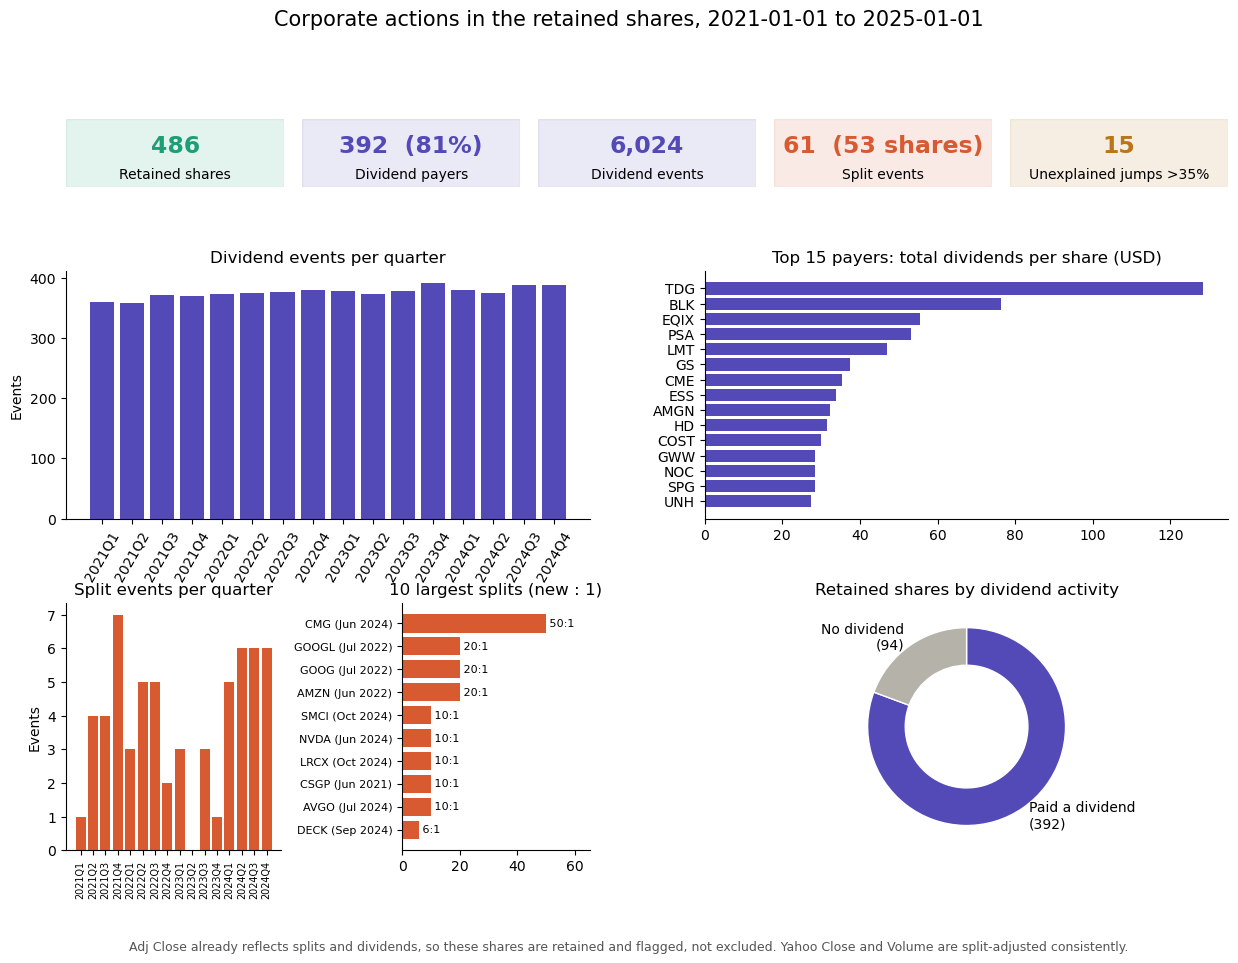

In [94]:
# ---------- corporate actions: diagnostic + infographic (retained shares only) ----------
import matplotlib.gridspec as gridspec
START_TS, END_TS = pd.Timestamp(start), pd.Timestamp(end)

# 1. why might the dividend check show nothing? look at the raw column first
print("Dividends column present   :", "Dividends" in df_all.columns)
print("Dividends non-missing rows :", int(df_all["Dividends"].notna().sum()), "| rows > 0:", int((df_all["Dividends"].fillna(0) > 0).sum()))

r = df_all[df_all["Ticker"].isin(keep)]                         # retained shares only
div_ev = r[r["Dividends"].fillna(0) > 0]
spl_ev = r[r["Stock Splits"].fillna(0) > 0]
n_ret, payers = len(keep), div_ev["Ticker"].nunique()
n_jump = int(jumps["Ticker"].isin(keep).sum())
print(f"Dividend events: {len(div_ev)} | payers: {payers} | total per share: ${div_ev['Dividends'].sum():,.2f} | split events: {len(spl_ev)}")
if len(div_ev) == 0:
    print("-> No dividend rows found. Re-run the download with actions=True and auto_adjust=False, then rebuild df_all.")

# 2. infographic
C = {"div": "#534AB7", "ok": "#1D9E75", "grey": "#B4B2A9", "split": "#D85A30", "warn": "#BA7517"}
fig = plt.figure(figsize=(15, 9.5))
gs = gridspec.GridSpec(3, 2, height_ratios=[0.55, 2, 2], hspace=0.45, wspace=0.22)

tiles = [("Retained shares", f"{n_ret}", C["ok"]),
         ("Dividend payers", f"{payers}  ({payers / max(n_ret, 1) * 100:.0f}%)", C["div"]),
         ("Dividend events", f"{len(div_ev):,}", C["div"]),
         ("Split events", f"{len(spl_ev)}  ({spl_ev['Ticker'].nunique()} shares)", C["split"]),
         ("Unexplained jumps >35%", f"{n_jump}", C["warn"])]
top = gs[0, :].subgridspec(1, len(tiles), wspace=0.08)
for i, (lab, val, col) in enumerate(tiles):
    a = fig.add_subplot(top[0, i]); a.axis("off")
    a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, color=col, alpha=0.12))
    a.text(0.5, 0.60, val, ha="center", va="center", fontsize=17, fontweight="bold", color=col, transform=a.transAxes)
    a.text(0.5, 0.18, lab, ha="center", va="center", fontsize=10, transform=a.transAxes)

# dividend events per quarter
ax1 = fig.add_subplot(gs[1, 0])
if len(div_ev):
    q = div_ev.groupby(div_ev["Date"].dt.to_period("Q")).size()
    ax1.bar(q.index.astype(str), q.values, color=C["div"]); ax1.tick_params(axis="x", rotation=60)
else:
    ax1.text(0.5, 0.5, "No dividend events found", ha="center", va="center", transform=ax1.transAxes)
ax1.set_title("Dividend events per quarter"); ax1.set_ylabel("Events")

# top dividend payers (total dividends per share, USD)
ax2 = fig.add_subplot(gs[1, 1])
if len(div_ev):
    tp = div_ev.groupby("Ticker")["Dividends"].sum().nlargest(15).sort_values()
    ax2.barh(tp.index, tp.values, color=C["div"])
else:
    ax2.text(0.5, 0.5, "No dividend events found", ha="center", va="center", transform=ax2.transAxes)
ax2.set_title("Top 15 payers: total dividends per share (USD)")

# splits: count per quarter (when) + the 10 largest ratios (how big), instead of labelling every split
sub = gs[2, 0].subgridspec(1, 2, wspace=0.6, width_ratios=[1.15, 1])
ax3a, ax3b = fig.add_subplot(sub[0, 0]), fig.add_subplot(sub[0, 1])
if len(spl_ev):
    sq = spl_ev.groupby(spl_ev["Date"].dt.to_period("Q")).size()
    sq = sq.reindex(pd.period_range(START_TS,END_TS - pd.Timedelta(days=1), freq="Q"), fill_value=0)
    ax3a.bar(sq.index.astype(str), sq.values, color=C["split"]); ax3a.tick_params(axis="x", rotation=90, labelsize=7)
    ax3a.set_title("Split events per quarter"); ax3a.set_ylabel("Events")
    big = spl_ev.nlargest(10, "Stock Splits").sort_values("Stock Splits")
    ax3b.barh([f"{t} ({d:%b %Y})" for t, d in zip(big["Ticker"], big["Date"])], big["Stock Splits"], color=C["split"])
    for i_, v_ in enumerate(big["Stock Splits"]):
        ax3b.text(v_, i_, f" {v_:g}:1", va="center", fontsize=8)
    ax3b.set_xlim(0, big["Stock Splits"].max() * 1.3); ax3b.tick_params(axis="y", labelsize=8)
    ax3b.set_title("10 largest splits (new : 1)")
else:
    for a_ in (ax3a, ax3b):
        a_.text(0.5, 0.5, "No split events in the retained shares", ha="center", va="center", transform=a_.transAxes)

# payers vs non-payers
ax4 = fig.add_subplot(gs[2, 1])
ax4.pie([payers, max(n_ret - payers, 0)], labels=[f"Paid a dividend\n({payers})", f"No dividend\n({n_ret - payers})"],
        colors=[C["div"], C["grey"]], startangle=90, counterclock=False, wedgeprops=dict(width=0.38, edgecolor="white"))
ax4.set_title("Retained shares by dividend activity")

for a in (ax1, ax2, ax3a, ax3b):
    for s_ in ("top", "right"): a.spines[s_].set_visible(False)
fig.suptitle(f"Corporate actions in the retained shares, {start} to {end}", fontsize=15, y=0.995)
fig.text(0.5, 0.005, "Adj Close already reflects splits and dividends, so these shares are retained and flagged, not excluded. "
         "Yahoo Close and Volume are split-adjusted consistently.", ha="center", fontsize=9, color="#555")
plt.savefig(f"{OUT_DIR}/corporate_actions_infographic.png", dpi=200, bbox_inches="tight"); plt.show()

In [31]:
df_clean.shape

(489435, 10)

### Weekly return and weekly beta

##### Mean weekly return

In [69]:
prices_wide = (df_clean
               .pivot(index='Date', columns='Ticker', values='Adj Close')
               .sort_index())

def calculate_weekly_returns(prices, shares=None):
    """prices: DataFrame, dates as rows and tickers as columns (Adj Close)."""
    if shares is not None:
        prices = prices[shares]
    prices = prices.copy()
    prices.index = pd.to_datetime(prices.index)
    weekly = prices.sort_index().resample("W-FRI").last()

    # keep only complete calendar weeks inside the study period
    week_monday = weekly.index - pd.Timedelta(days=4)
    weekly = weekly[(week_monday >= start) & (weekly.index < end)]

    return weekly.pct_change(fill_method=None)

weekly_return = calculate_weekly_returns(prices_wide)
weekly_return = weekly_return.iloc[1:]       # first week has no preceding week (blank return)
print(weekly_return.shape)

(207, 487)


In [70]:
weekly_return = calculate_weekly_returns(prices_wide)

In [72]:
BENCH_SYMBOL = '^GSPC'

market_ret = weekly_return[BENCH_SYMBOL]
share_ret  = weekly_return.drop(columns=BENCH_SYMBOL)

# Use only weeks where both the share and the benchmark have a return (common week labels)
aligned = share_ret.where(market_ret.notna(), axis=0)

# Arithmetic mean weekly return: one value per share
mean_weekly_return = aligned.mean().rename('Mean_Weekly_Return')

print('Shares:', len(mean_weekly_return))
print('Weekly observations per share:', aligned.notna().sum().min(), 'to', aligned.notna().sum().max())
print(mean_weekly_return.describe())
mean_weekly_return.sort_values(ascending=False).head(10)

Shares: 486
Weekly observations per share: 207 to 207
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
Name: Mean_Weekly_Return, dtype: float64


Ticker
SMCI    0.017772
NVDA    0.013624
VRT     0.012583
VST     0.011395
FIX     0.011297
CVNA    0.010964
ANET    0.010310
TRGP    0.010152
AVGO    0.010133
AXON    0.009767
Name: Mean_Weekly_Return, dtype: float64

In [73]:
t = mean_weekly_return.index[0]
print(t, mean_weekly_return[t], weekly_return[t].dropna().mean())   # the two numbers should match

A 0.0011206089041255402 0.0011206089041255402


#### Weekly beta

In [50]:
def calculate_weekly_beta(weekly_return, market_return, min_weeks=52):
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_return.columns:
        paired = pd.concat(
            [weekly_return[share].rename("share"),
             market_return.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [51]:
BENCH_SYMBOL = '^GSPC'

market_ret = weekly_return[BENCH_SYMBOL]                  # benchmark column
share_ret  = weekly_return.drop(columns=BENCH_SYMBOL)     # shares only

beta_df = calculate_weekly_beta(share_ret, market_ret)
print(beta_df['Paired_weeks'].value_counts())             # expect 207 for every share
beta_df.describe()

Paired_weeks
208    486
Name: count, dtype: int64


,Beta,Paired_weeks
count,486.000000,486.0
mean,0.972814,208.0
std,0.407177,0.0
min,0.056026,208.0
25%,0.667232,208.0
50%,0.945883,208.0
75%,1.177632,208.0
max,3.778556,208.0


In [52]:
beta_df.head()

,Beta,Paired_weeks
Share,,
A,1.072942,208
AAPL,1.175479,208
ABBV,0.425047,208
ABNB,1.471139,208
ABT,0.584765,208


### Recency Calculation

In [57]:
OBS_DATE = pd.Timestamp('2024-12-31')
vol = (df_clean[df_clean['Ticker'] != BENCH_SYMBOL]
       .pivot(index='Date', columns='Ticker', values='Volume')
       .sort_index())
vol = vol.loc[:OBS_DATE]
print('Last date in data:', vol.index[-1].date())

baseline = vol.shift(1).rolling(20).mean()

# 3. High-volume day: volume > 2 x baseline (first 20 sessions have no baseline, so never qualify)
high = (vol > 2 * baseline) & baseline.notna()

# 4. Latest qualifying day per share, over the whole valid history
def last_event(col):
    days = col.index[col]
    return days[-1] if len(days) else pd.NaT

last_event_date = high.apply(last_event)

# 5. Recency = calendar days from that event to the observation date (NaN if no event, never 0)
recency = (OBS_DATE - last_event_date).dt.days.rename('Recency')

rfm = pd.concat([last_event_date.rename('Last_Event_Date'), recency], axis=1)
print('Shares with no event (Recency missing):', int(rfm['Recency'].isna().sum()))
rfm.head()

Last date in data: 2024-12-31
Shares with no event (Recency missing): 0


,Last_Event_Date,Recency
Ticker,,
A,2024-12-20,11
AAPL,2024-12-20,11
ABBV,2024-12-20,11
ABNB,2024-12-20,11
ABT,2024-12-20,11


In [58]:
rfm

,Last_Event_Date,Recency
Ticker,,
A,2024-12-20,11
AAPL,2024-12-20,11
ABBV,2024-12-20,11
ABNB,2024-12-20,11
ABT,2024-12-20,11
...,...,...
XYZ,2024-11-12,49
YUM,2024-11-05,56
ZBH,2024-12-20,11


In [59]:
print(rfm['Recency'].value_counts().head())

Recency
11    353
36     17
55     11
60      6
46      6
Name: count, dtype: int64


### Frequency Calculation

In [60]:
RFM_WIN = 60

# 1. Last 60 trading sessions ending on the observation date
#    ('high' was built on the FULL history in the Recency cell, so every window day has its 20-session baseline)
window = high.loc[:OBS_DATE].tail(RFM_WIN)
assert len(window) == RFM_WIN and window.index[-1] == OBS_DATE
print(f'Window: {window.index[0].date()} -> {window.index[-1].date()} ({len(window)} sessions)')

# 2. Frequency = number of qualifying days in the window, per share
frequency = window.sum().astype(int).rename('Frequency')

# 3. Add it to the RFM table
rfm['Frequency'] = frequency

print(frequency.describe())
print('\nDistribution of Frequency:')
print(frequency.value_counts().sort_index().to_string())

Window: 2024-10-07 -> 2024-12-31 (60 sessions)
count    486.000000
mean       2.989712
std        1.330800
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
Name: Frequency, dtype: float64

Distribution of Frequency:
Frequency
0     10
1     42
2    130
3    149
4     94
5     45
6     11
7      3
8      2


### Monetary Calculation

In [62]:
close = (df_clean[df_clean['Ticker'] != BENCH_SYMBOL]
         .pivot(index='Date', columns='Ticker', values='Close')
         .sort_index()
         .loc[:OBS_DATE])
close = close[vol.columns]                       # same columns, same order as volume

# 2. Daily traded value = Close x Volume
traded_value = close * vol.loc[:OBS_DATE]

# 3. Latest 60 trading sessions ending on the observation date
window_tv = traded_value.tail(RFM_WIN)
assert len(window_tv) == RFM_WIN and window_tv.index[-1] == OBS_DATE
print(f'Window: {window_tv.index[0].date()} -> {window_tv.index[-1].date()} ({len(window_tv)} sessions)')

# 4. Monetary = sum of the 60 daily values (USD)
monetary = window_tv.sum().rename('Monetary')
rfm['Monetary'] = monetary

print(monetary.describe().apply(lambda x: f'{x:,.0f}'))
print('\nTop 5 by traded value:')
print(monetary.sort_values(ascending=False).head(5).apply(lambda x: f'${x:,.0f}'))

Window: 2024-10-07 -> 2024-12-31 (60 sessions)
count                  486
mean        39,404,191,889
std        129,138,833,233
min          1,297,482,617
25%         10,195,173,392
50%         16,683,821,505
75%         32,276,893,044
max      1,847,697,379,222
Name: Monetary, dtype: object

Top 5 by traded value:
Ticker
TSLA    $1,847,697,379,222
NVDA    $1,825,336,654,239
AAPL      $623,303,377,707
MSFT      $534,898,232,235
AMZN      $468,177,023,567
Name: Monetary, dtype: object


In [63]:
rfm

,Last_Event_Date,Recency,Frequency,Monetary
Ticker,,,,
A,2024-12-20,11,2,1.400180e+10
AAPL,2024-12-20,11,2,6.233034e+11
ABBV,2024-12-20,11,3,6.837054e+10
ABNB,2024-12-20,11,3,3.652850e+10
ABT,2024-12-20,11,1,3.523027e+10
...,...,...,...,...
XYZ,2024-11-12,49,5,4.052406e+10
YUM,2024-11-05,56,1,1.339492e+10
ZBH,2024-12-20,11,2,9.609458e+09


### 2nd Question

In [79]:
BENCH_SYMBOL = '^GSPC'

# 1. Share and week rows (the week labels come from your weekly_return table)
base = (weekly_return
        .drop(columns=BENCH_SYMBOL)
        .rename_axis('Week')
        .reset_index()
        .melt(id_vars='Week', var_name='Share', value_name='Weekly_Return')
        .sort_values(['Share', 'Week'])
        .reset_index(drop=True))

# 2. Make the two per-share tables use the same key column: Share
mwr = mean_weekly_return.rename('Mean_Weekly_Return').rename_axis('Share').reset_index()   # if it is a Series
bt  = beta_df[['Beta']].rename_axis('Share').reset_index()

# 3. Merge: every row gets that share's mean return and beta
combined = (base[['Week', 'Share']]
            .merge(mwr, on='Share', how='left')
            .merge(bt,  on='Share', how='left'))

print(combined.shape)
combined.head()

(101088, 4)


,Week,Share,Mean_Weekly_Return,Beta
0,2021-01-08,A,0.001121,1.072942
1,2021-01-15,A,0.001121,1.072942
2,2021-01-22,A,0.001121,1.072942
3,2021-01-29,A,0.001121,1.072942
4,2021-02-05,A,0.001121,1.072942


In [65]:
rfm.head()

,Last_Event_Date,Recency,Frequency,Monetary
Ticker,,,,
A,2024-12-20,11,2,1.400180e+10
AAPL,2024-12-20,11,2,6.233034e+11
ABBV,2024-12-20,11,3,6.837054e+10
ABNB,2024-12-20,11,3,3.652850e+10
ABT,2024-12-20,11,1,3.523027e+10


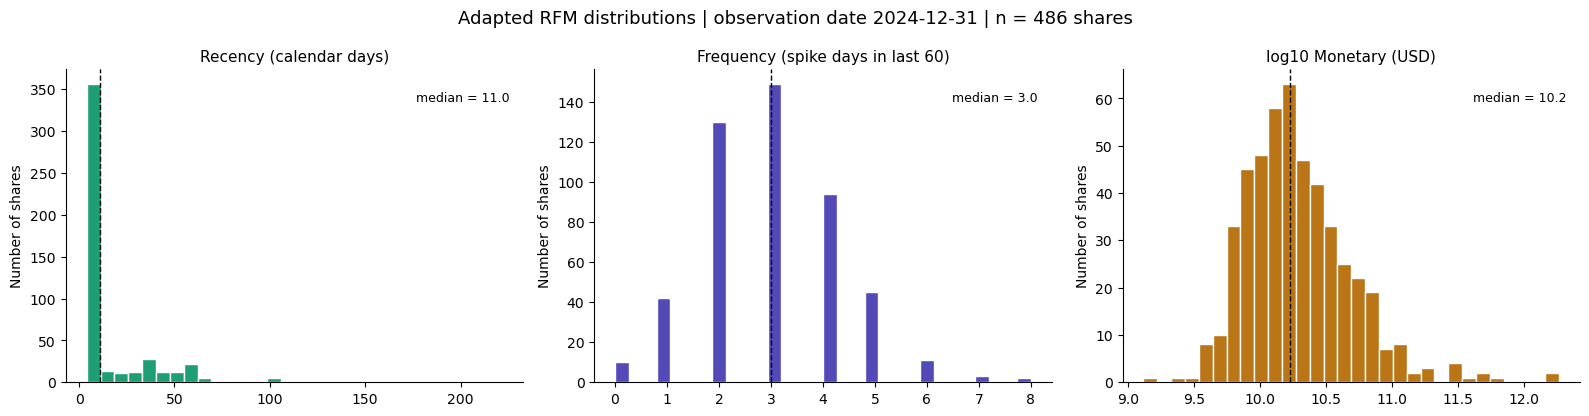

In [80]:
import numpy as np
import matplotlib.pyplot as plt

plot_df = rfm[['Recency', 'Frequency', 'Monetary']].dropna().copy()
plot_df['Log10_Monetary'] = np.log10(plot_df['Monetary'])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
panels = [('Recency', 'Recency (calendar days)', '#1D9E75'),
          ('Frequency', 'Frequency (spike days in last 60)', '#534AB7'),
          ('Log10_Monetary', 'log10 Monetary (USD)', '#BA7517')]

for a, (col, label, colour) in zip(ax, panels):
    a.hist(plot_df[col], bins=30, color=colour, edgecolor='white')
    a.axvline(plot_df[col].median(), color='black', ls='--', lw=1)
    a.set_title(label, fontsize=11)
    a.set_ylabel('Number of shares')
    a.text(0.97, 0.93, f'median = {plot_df[col].median():.1f}', transform=a.transAxes,
           ha='right', va='top', fontsize=9)
    for s in ('top', 'right'):
        a.spines[s].set_visible(False)

fig.suptitle(f'Adapted RFM distributions | observation date {OBS_DATE.date()} | n = {len(plot_df)} shares',
             fontsize=13)
plt.tight_layout()
plt.savefig('outputs/rfm_distributions.png', dpi=200)
plt.show()

In [82]:
! pip install -U threadpoolctl scikit-learn

  Obtaining dependency information for threadpoolctl from https://files.pythonhosted.org/packages/54/1b/831f2de4840a25db1dd7b1afea433ccafe6bb10aca07e13264f2079462d0/threadpoolctl-3.8.0-py3-none-any.whl.metadata
  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/29/8a/8d1e888fe3d0dd4e2a1f3356dad703eed569aaf673e222b6f647005ad30f/scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata
  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Obtaining dependency information for joblib>=1.4.0 from https://files.pythonhosted.org/packages/18/53/84099323c2ec4be98d935f63c033ac4151ee83836ca1050ede3b3aadf155/joblib-1.6.0-py3-none-any.whl.metadata
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Obtaining dependency information for cloudpickle>=3.0 from https://files.pythonhosted.org/packages/88/39/799be3f2f0f38cc727ee3b4f1445fe6d5e4133064ec2e4115069418a5bb6/cloudpickle-3.1.2-py3-none-any.whl.metadata
  Using cached

Shares in common valid set: 486
RAW FEATURES
                            mean        median           std           min           max    skew  IQR_outliers  outlier_%
Mean_Weekly_Return  3.000000e-03  3.000000e-03  3.000000e-03 -4.000000e-03  1.800000e-02   0.868            15        3.1
Beta                9.730000e-01  9.460000e-01  4.070000e-01  5.600000e-02  3.779000e+00   1.108            10        2.1
Recency             2.040700e+01  1.100000e+01  2.134200e+01  4.000000e+00  2.220000e+02   3.646           115       23.7
Frequency           2.990000e+00  3.000000e+00  1.331000e+00  0.000000e+00  8.000000e+00   0.425             2        0.4
Monetary            3.940419e+10  1.668382e+10  1.291388e+11  1.297483e+09  1.847697e+12  11.684            45        9.3


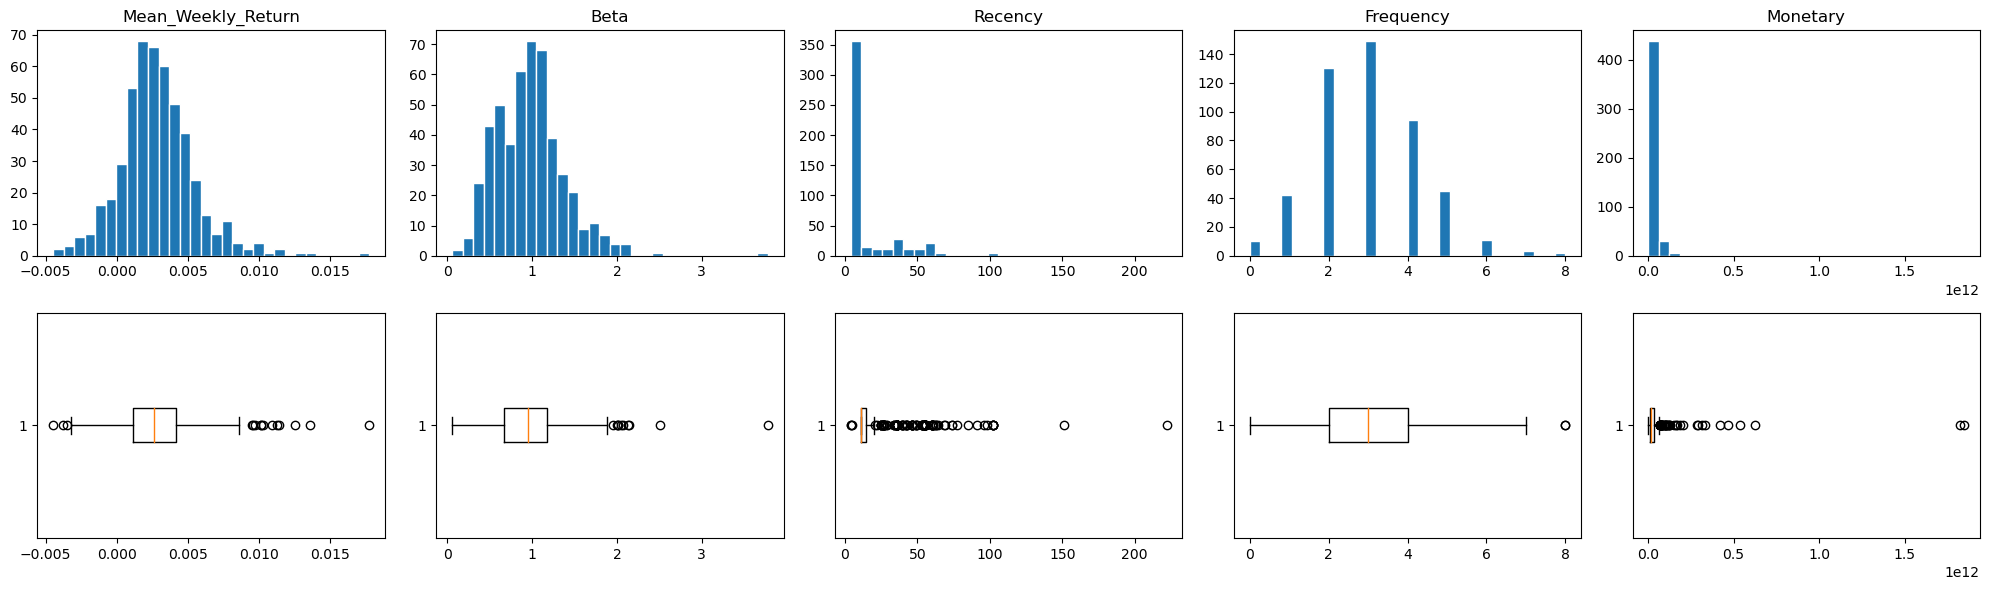


Skew of Monetary before / after log1p: 11.68 -> 1.08

ACTIVITY MATRIX AFTER log1p
                  mean  median     std     min      max   skew  IQR_outliers  outlier_%
Recency         20.407  11.000  21.342   4.000  222.000  3.646           115       23.7
Frequency        2.990   3.000   1.331   0.000    8.000  0.425             2        0.4
log1p_Monetary  23.682  23.538   0.942  20.984   28.245  1.079            13        2.7

Standardised means ~0, std ~1:
      Mean_Weekly_Return   Beta
mean              -0.000 -0.000
std                1.001  1.001
      Recency  Frequency  log1p_Monetary
mean   -0.000     -0.000          -0.000
std     1.001      1.001           1.001

FOUR BASELINE SOLUTIONS
     Matrix        Method  k  Silhouette           Sizes
Risk_Return        KMeans  3       0.329 [165, 202, 119]
Risk_Return Agglomerative  3       0.295  [304, 153, 29]
   Activity        KMeans  3       0.325  [270, 64, 152]
   Activity Agglomerative  3       0.304  [250, 82, 154]


In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED, N_INIT, MIN_FRAC = 42, 50, 0.05
np.random.seed(SEED)

# ---------- 1. Common valid share set (all five features present) ----------
mwr = mean_weekly_return.copy()
if isinstance(mwr, pd.DataFrame):                       # accept either a Series or a DataFrame
    mwr = mwr.set_index(mwr.columns[0]).iloc[:, 0]
mwr.index.name = 'Share'

all_feat = pd.concat([mwr.rename('Mean_Weekly_Return'),
                      beta_df['Beta'].rename_axis('Share'),
                      rfm[['Recency', 'Frequency', 'Monetary']].rename_axis('Share')],
                     axis=1, join='inner').dropna()
print('Shares in common valid set:', len(all_feat))

# ---------- 2. Inspect skew and outliers (raw features) ----------
def inspect(df):
    q1, q3 = df.quantile(.25), df.quantile(.75)
    iqr = q3 - q1
    out = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
    return pd.DataFrame({'mean': df.mean(), 'median': df.median(), 'std': df.std(),
                         'min': df.min(), 'max': df.max(),
                         'skew': df.skew(), 'IQR_outliers': out,
                         'outlier_%': (out / len(df) * 100).round(1)})

print('RAW FEATURES'); print(inspect(all_feat).round(3).to_string())

fig, ax = plt.subplots(2, 5, figsize=(20, 6))
for i, c in enumerate(all_feat.columns):
    ax[0, i].hist(all_feat[c], bins=30, edgecolor='white'); ax[0, i].set_title(c)
    ax[1, i].boxplot(all_feat[c], vert=False)
plt.tight_layout(); plt.show()

# ---------- 3. Two separate feature matrices ----------
risk_return = all_feat[['Mean_Weekly_Return', 'Beta']].copy()
activity    = all_feat[['Recency', 'Frequency', 'Monetary']].copy()

# log1p on Monetary only (as required)
activity['Monetary'] = np.log1p(activity['Monetary'])
activity = activity.rename(columns={'Monetary': 'log1p_Monetary'})
print('\nSkew of Monetary before / after log1p:',
      round(all_feat['Monetary'].skew(), 2), '->', round(activity['log1p_Monetary'].skew(), 2))
print('\nACTIVITY MATRIX AFTER log1p'); print(inspect(activity).round(3).to_string())

# ---------- 4. Standardise each matrix separately ----------
def standardise(df):
    return pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=df.columns)

X_risk = standardise(risk_return)
X_act  = standardise(activity)
print('\nStandardised means ~0, std ~1:')
print(X_risk.agg(['mean', 'std']).round(3)); print(X_act.agg(['mean', 'std']).round(3))

# ---------- 5. Four baseline solutions ----------
K = 3      # baseline value; the choice of k is justified in the next section
matrices = {'Risk_Return': X_risk, 'Activity': X_act}
labels = pd.DataFrame(index=all_feat.index)
summary = []
def fit(method, X, k, seed=SEED):
    if method == "KMeans":
        return KMeans(n_clusters=k, n_init=N_INIT, random_state=seed, algorithm="elkan").fit_predict(X)
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)

matrices = {"Risk_Return": X_risk, "Activity": X_act}
K = 3
summary = []
baseline_labels = pd.DataFrame(index=all_feat.index)
for name, X in matrices.items():
    for method in ["KMeans", "Agglomerative"]:
        lab = fit(method, X, K)
        baseline_labels[f"{name}_{method}"] = lab
        summary.append({"Matrix": name, "Method": method, "k": K, "Silhouette": silhouette_score(X, lab), "Sizes": np.bincount(lab).tolist()})
print("\nFOUR BASELINE SOLUTIONS"); print(pd.DataFrame(summary).round(3).to_string(index=False))
all_feat.join(baseline_labels).to_csv(f"{OUT_DIR}/feature_table_baseline_assignments_k3.csv")

### Agglomerative clustering

     Matrix        Method  k  Inertia  Silhouette  Min_%                             Sizes  Inertia_drop_%  Feasible
Risk_Return        KMeans  2  621.223       0.387   29.4                        [343, 143]             NaN      True
Risk_Return        KMeans  3  461.159       0.329   24.5                   [202, 165, 119]            25.8      True
Risk_Return        KMeans  4  371.508       0.327    8.2               [160, 154, 132, 40]            19.4      True
Risk_Return        KMeans  5  309.729       0.340    6.0           [164, 135, 108, 50, 29]            16.6      True
Risk_Return        KMeans  6  265.028       0.335    1.0        [156, 127, 105, 50, 43, 5]            14.4     False
Risk_Return        KMeans  7  227.014       0.331    1.0      [137, 91, 86, 73, 48, 46, 5]            14.3     False
Risk_Return        KMeans  8  194.239       0.354    1.0  [135, 80, 78, 76, 43, 40, 29, 5]            14.4     False
Risk_Return Agglomerative  2      NaN       0.258   31.5        

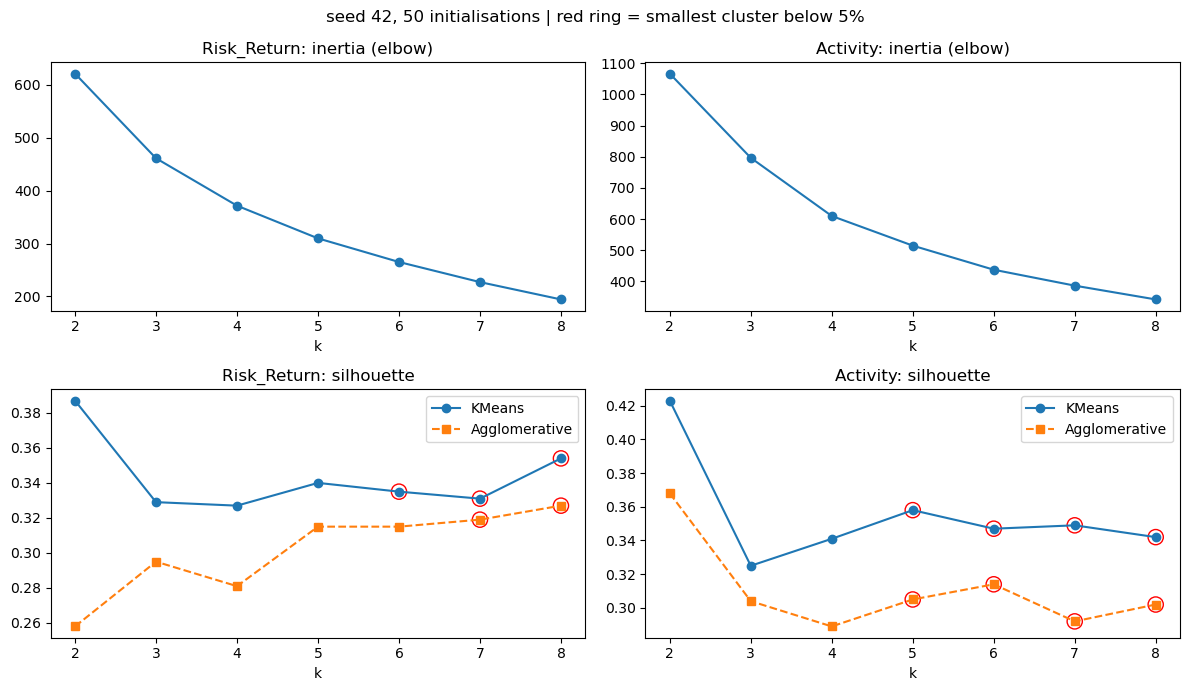


=== Risk_Return, Ward, k = 3 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0026       1.0825  304  62.6
1                           0.0023       0.5583  153  31.5
2                           0.0083       1.3703   29   6.0

=== Risk_Return, Ward, k = 4 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0035       1.1326  197  40.5
1                           0.0023       0.5583  153  31.5
2                           0.0083       1.3703   29   6.0
3                           0.0008       1.0009  107  22.0

=== Risk_Return, Ward, k = 5 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0023       0.5583  153  31.5
1                           0.0027       1.5508   56  11.5
2            

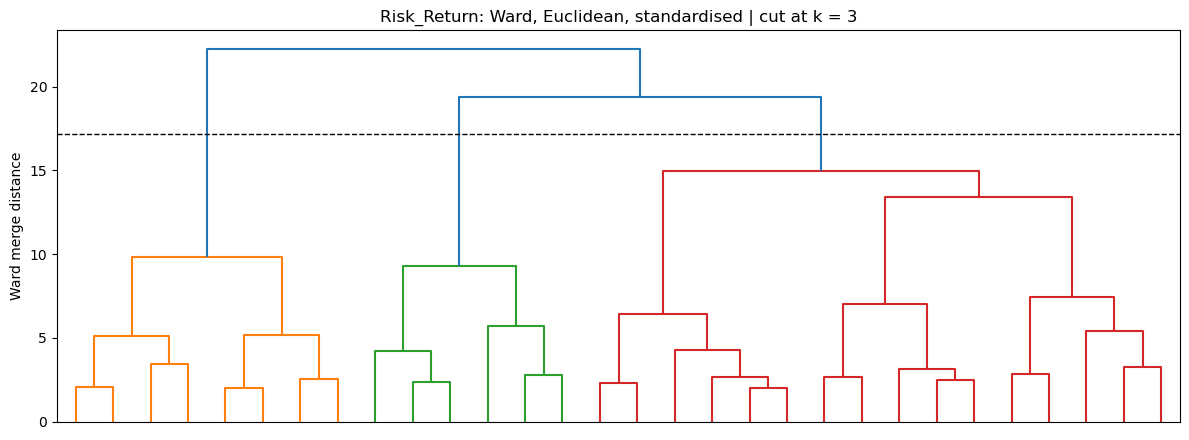

Risk_Return: k = 3 | cophenetic r = 0.458 | K-means vs Ward ARI = 0.33


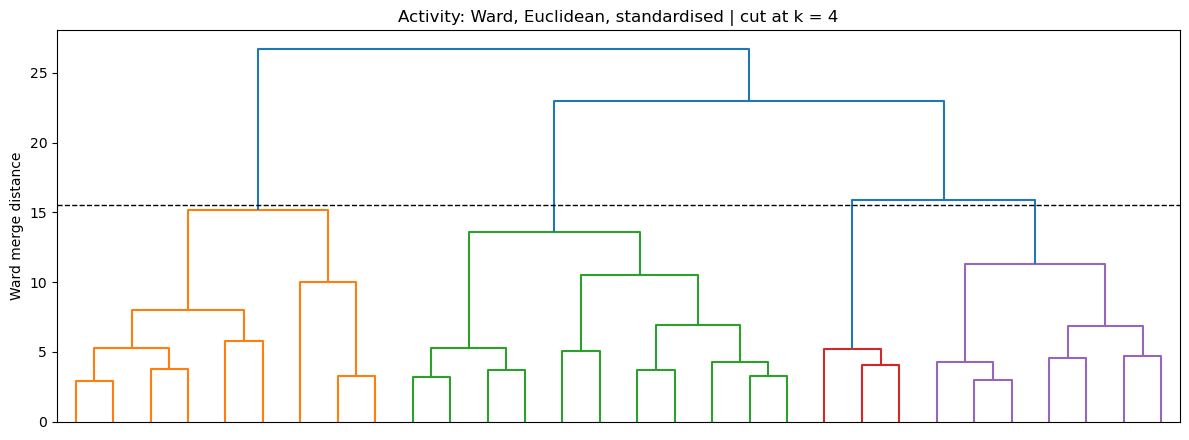

Activity: k = 4 | cophenetic r = 0.508 | K-means vs Ward ARI = 0.34


In [96]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
SEED, N_INIT, MIN_FRAC = 42, 50, 0.05
np.random.seed(SEED)

# ---------- A. compare k = 2..8: silhouette, inertia, sizes ----------
rows = []
for name, X in matrices.items():
    for method in ["KMeans", "Agglomerative"]:
        for k in range(2, 9):
            lab = fit(method, X, k); s_ = np.bincount(lab)
            inertia = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED, algorithm="elkan").fit(X).inertia_ if method == "KMeans" else np.nan
            rows.append({"Matrix": name, "Method": method, "k": k, "Inertia": inertia,
                         "Silhouette": round(silhouette_score(X, lab), 3),
                         "Min_%": round(s_.min() / len(X) * 100, 1), "Sizes": sorted(s_.tolist(), reverse=True)})
comp = pd.DataFrame(rows)
comp["Inertia_drop_%"] = (comp.groupby(["Matrix", "Method"])["Inertia"].pct_change() * -100).round(1)
comp["Feasible"] = comp["Min_%"] >= MIN_FRAC * 100
print(comp.round(3).to_string(index=False))
comp.to_csv(f"{OUT_DIR}/cluster_count_comparison.csv", index=False)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for j, name in enumerate(matrices):
    dk = comp[(comp.Matrix == name) & (comp.Method == "KMeans")]
    ax[0, j].plot(dk["k"], dk["Inertia"], "o-"); ax[0, j].set_title(f"{name}: inertia (elbow)")
    for method, st in [("KMeans", "o-"), ("Agglomerative", "s--")]:
        d_ = comp[(comp.Matrix == name) & (comp.Method == method)]
        ax[1, j].plot(d_["k"], d_["Silhouette"], st, label=method)
        bad = d_[~d_["Feasible"]]; ax[1, j].scatter(bad["k"], bad["Silhouette"], s=120, facecolors="none", edgecolors="red")
    ax[1, j].set_title(f"{name}: silhouette"); ax[1, j].legend()
    for a in ax[:, j]: a.set_xticks(range(2, 9)); a.set_xlabel("k")
plt.suptitle(f"seed {SEED}, {N_INIT} initialisations | red ring = smallest cluster below 5%")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/k_selection.png", dpi=200); plt.show()

# ---------- B. profiles of candidate k (Ward, original units) ----------
COLS = {"Risk_Return": ["Mean_Weekly_Return", "Beta"], "Activity": ["Recency", "Frequency", "Monetary"]}
def profile(labels, cols):
    g = all_feat.assign(Cluster=labels).groupby("Cluster")
    out = g[cols].median().add_suffix("_median")
    out["n"] = g.size(); out["%"] = (out["n"] / len(all_feat) * 100).round(1)
    return out.round(4)
for name, X in matrices.items():
    for k in [3, 4, 5]:
        print(f"\n=== {name}, Ward, k = {k} ==="); print(profile(fit("Agglomerative", X, k), COLS[name]).to_string())

# ---------- C. SET THE FINAL k after reading A and B ----------
SELECTED = {"Risk_Return": 3, "Activity": 4}

# ---------- D. one Ward dendrogram per matrix, cut at the selected k ----------
for name, X in matrices.items():
    k = SELECTED[name]
    Z = linkage(X.values, method="ward", metric="euclidean")
    cut = (Z[-k, 2] + Z[-(k - 1), 2]) / 2
    assert len(set(fcluster(Z, k, "maxclust"))) == k
    fig, ax = plt.subplots(figsize=(12, 4.5))
    dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=cut, ax=ax)
    ax.axhline(cut, color="black", ls="--", lw=1)
    ax.set_title(f"{name}: Ward, Euclidean, standardised | cut at k = {k}"); ax.set_ylabel("Ward merge distance")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/dendrogram_{name}.png", dpi=200); plt.show()
    c_, _ = cophenet(Z, pdist(X.values))
    print(f"{name}: k = {k} | cophenetic r = {c_:.3f} | K-means vs Ward ARI = {adjusted_rand_score(fit('KMeans', X, k), fit('Agglomerative', X, k)):.2f}")

     Matrix        Method  k  Silhouette  Min_%                             Sizes  Feasible
Risk_Return        KMeans  2       0.387   29.4                        [343, 143]      True
Risk_Return        KMeans  3       0.329   24.5                   [202, 165, 119]      True
Risk_Return        KMeans  4       0.327    8.2               [160, 154, 132, 40]      True
Risk_Return        KMeans  5       0.338    5.8           [165, 126, 112, 55, 28]      True
Risk_Return        KMeans  6       0.328    3.3        [138, 119, 79, 78, 56, 16]     False
Risk_Return        KMeans  7       0.331    1.0      [137, 91, 86, 73, 48, 46, 5]     False
Risk_Return        KMeans  8       0.358    1.0  [140, 78, 77, 74, 45, 38, 29, 5]     False
Risk_Return Agglomerative  2       0.258   31.5                        [333, 153]      True
Risk_Return Agglomerative  3       0.295    6.0                    [304, 153, 29]      True
Risk_Return Agglomerative  4       0.281    6.0               [197, 153, 107, 29

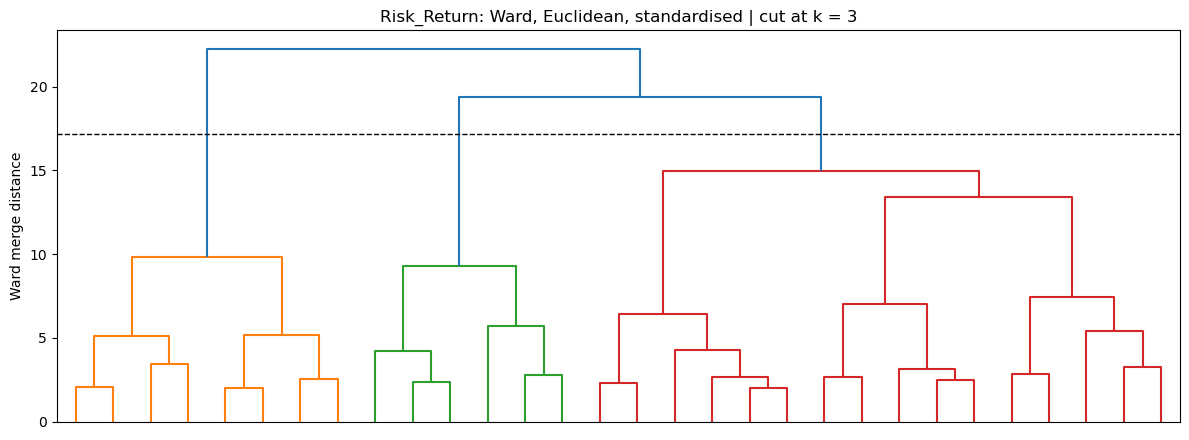

Risk_Return: k = 3 | cophenetic r = 0.458 | K-means vs Ward ARI = 0.33


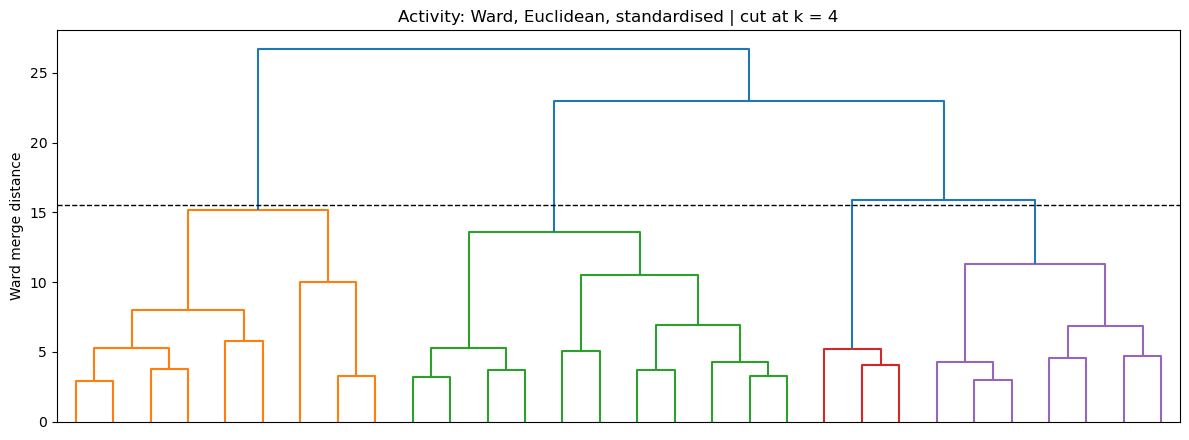

Activity: k = 4 | cophenetic r = 0.508 | K-means vs Ward ARI = 0.34


     Matrix  k  Inertia  Silhouette  Min_%                             Sizes  Inertia_drop_%  Feasible
Risk_Return  2  621.223       0.387   29.4                        [343, 143]             NaN      True
Risk_Return  3  461.159       0.329   24.5                   [202, 165, 119]            25.8      True
Risk_Return  4  371.508       0.327    8.2               [160, 154, 132, 40]            19.4      True
Risk_Return  5  309.729       0.340    6.0           [164, 135, 108, 50, 29]            16.6      True
Risk_Return  6  265.028       0.335    1.0        [156, 127, 105, 50, 43, 5]            14.4     False
Risk_Return  7  227.014       0.331    1.0      [137, 91, 86, 73, 48, 46, 5]            14.3     False
Risk_Return  8  194.239       0.354    1.0  [135, 80, 78, 76, 43, 40, 29, 5]            14.4     False
   Activity  2 1066.832       0.423   14.0                         [418, 68]             NaN      True
   Activity  3  796.614       0.325   13.2                    [270, 152, 

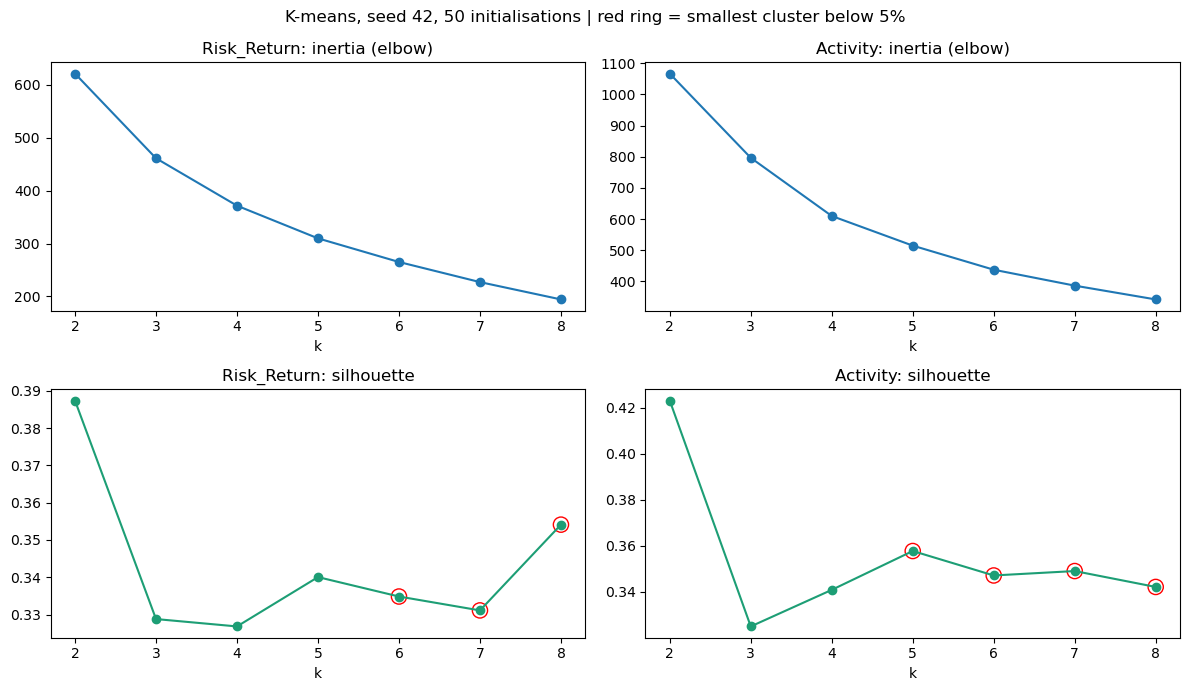

Risk_Return, k = 3: agreement with 4 other seeds (ARI) = [1. 1. 1. 1.]
   n_init=1 vs n_init=50 inertia: 461.16 vs 461.16
Activity, k = 4: agreement with 4 other seeds (ARI) = [1. 1. 1. 1.]
   n_init=1 vs n_init=50 inertia: 698.42 vs 609.83

=== Risk_Return profile, k = 3 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0012       1.0782  165  34.0
1                           0.0026       0.6218  202  41.6
2                           0.0053       1.2211  119  24.5

=== Activity profile, k = 4 ===
         Recency_median  Frequency_median  Monetary_median    n     %
Cluster                                                              
0                  11.0               2.0     1.333641e+10  212  43.6
1                  11.0               4.0     1.282589e+10  122  25.1
2                  55.0               2.0     2.124212e+10   61  12.6
3                  11.0               3.0    

In [97]:
# ---------- K-means: reproducibility and profiles at the selected k ----------
for name, X in matrices.items():
    k = SELECTED[name]
    base_lab = fit("KMeans", X, k, seed=SEED)
    aris = [adjusted_rand_score(base_lab, fit("KMeans", X, k, seed=s_)) for s_ in [1, 7, 99, 2024]]
    print(f"{name}, k = {k}: agreement with 4 other seeds (ARI) = {np.round(aris, 3)}")
    print(f"   inertia n_init=1: {KMeans(k, n_init=1, random_state=3, algorithm='elkan').fit(X).inertia_:.2f}"
          f" vs n_init={N_INIT}: {KMeans(k, n_init=N_INIT, random_state=SEED, algorithm='elkan').fit(X).inertia_:.2f}")
    print(f"=== {name} K-means profile, k = {k} ==="); print(profile(base_lab, COLS[name]).to_string())

final_labels = pd.DataFrame(index=all_feat.index)
for name, X in matrices.items():
    for method in ["KMeans", "Agglomerative"]:
        final_labels[f"{name}_{method}"] = fit(method, X, SELECTED[name])
final_labels.to_csv(f"{OUT_DIR}/final_cluster_labels.csv")

Risk_Return, k = 3: agreement with 4 other seeds (ARI) = [1. 1. 1. 1.]
   inertia n_init=1: 461.16 vs n_init=50: 461.16
=== Risk_Return K-means profile, k = 3 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0012       1.0782  165  34.0
1                           0.0026       0.6218  202  41.6
2                           0.0053       1.2211  119  24.5
Activity, k = 4: agreement with 4 other seeds (ARI) = [1. 1. 1. 1.]
   inertia n_init=1: 698.42 vs n_init=50: 609.83
=== Activity K-means profile, k = 4 ===
         Recency_median  Frequency_median  Monetary_median    n     %
Cluster                                                              
0                  11.0               2.0     1.333641e+10  212  43.6
1                  11.0               4.0     1.282589e+10  122  25.1
2                  55.0               2.0     2.124212e+10   61  12.6
3                  11.0            

### 2.4 Cluster profiles and algorithm comparison


=== Risk_Return | KMeans | k = 3 (medians, original units) ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0012       1.0782  165  34.0
1                           0.0026       0.6218  202  41.6
2                           0.0053       1.2211  119  24.5

=== Risk_Return | Agglomerative | k = 3 (medians, original units) ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0026       1.0825  304  62.6
1                           0.0023       0.5583  153  31.5
2                           0.0083       1.3703   29   6.0

=== Activity | KMeans | k = 4 (medians, original units) ===
         Recency_median  Frequency_median  Monetary_median    n     %
Cluster                                                              
0                  11.0               2.0     1.333641e+10  212  43.6
1   

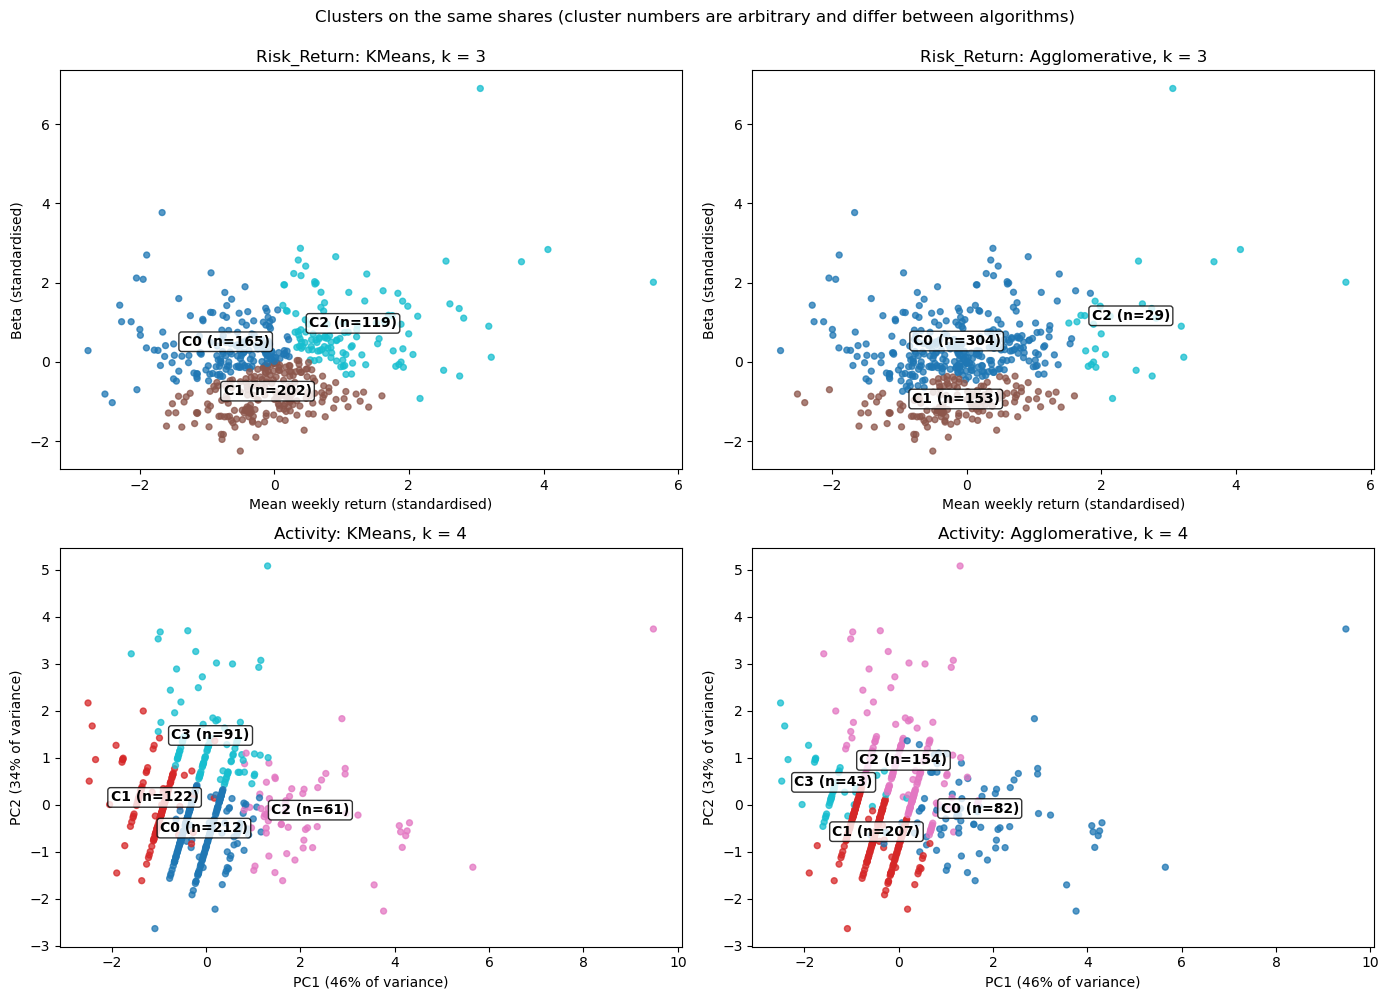


Risk_Return: cross-tabulation, shares = 486
Ward      0    1   2
KMeans              
0       162    3   0
1        52  150   0
2        90    0  29

Activity: cross-tabulation, shares = 486
Ward     0    1   2   3
KMeans                 
0       14  146  52   0
1        4   61  14  43
2       57    0   4   0
3        7    0  84   0

     Matrix  k  Shares   ARI  Matched_agreement_%  Silhouette_KMeans  Silhouette_Ward  DaviesBouldin_KMeans  DaviesBouldin_Ward
Risk_Return  3     486 0.335                 70.2              0.329            0.295                 1.010               1.016
   Activity  4     486 0.343                 67.9              0.341            0.289                 0.937               1.022


In [98]:
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score
from scipy.optimize import linear_sum_assignment

# ---- profiles in ORIGINAL units for both algorithms ----
for name in matrices:
    for method in ["KMeans", "Agglomerative"]:
        print(f"\n=== {name} | {method} | k = {SELECTED[name]} (medians, original units) ===")
        print(profile(final_labels[f"{name}_{method}"].values, COLS[name]).to_string())

# ---- labelled 2D visualisation ----
# Risk/return has only two features, so it is plotted directly (no reduction).
# Activity has three, so PCA projects the standardised data to 2D; axes show the variance each component keeps.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for r_, (name, X) in enumerate(matrices.items()):
    if name == "Risk_Return":
        xy = X.values; xl, yl = "Mean weekly return (standardised)", "Beta (standardised)"
    else:
        p2 = PCA(n_components=2).fit(X); xy = p2.transform(X); ev = p2.explained_variance_ratio_
        xl, yl = f"PC1 ({ev[0] * 100:.0f}% of variance)", f"PC2 ({ev[1] * 100:.0f}% of variance)"
        print("\nPCA loadings (activity):"); print(pd.DataFrame(p2.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(3))
        print(f"2D projection keeps {ev.sum() * 100:.0f}% of the variance; distances in the plot are approximate.")
    for c_, method in enumerate(["KMeans", "Agglomerative"]):
        lab = final_labels[f"{name}_{method}"].values; ax = axes[r_, c_]
        ax.scatter(xy[:, 0], xy[:, 1], c=lab, cmap="tab10", s=18, alpha=0.75)
        for k_ in np.unique(lab):
            m_ = lab == k_
            ax.annotate(f"C{k_} (n={m_.sum()})", xy[m_].mean(axis=0), ha="center", fontsize=10, fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
        ax.set_title(f"{name}: {method}, k = {SELECTED[name]}"); ax.set_xlabel(xl); ax.set_ylabel(yl)
plt.suptitle("Clusters on the same shares (cluster numbers are arbitrary and differ between algorithms)", y=0.995)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cluster_scatter_2d.png", dpi=200); plt.show()

# ---- algorithm comparison on the SAME shares ----
rows = []
for name, X in matrices.items():
    a_, b_ = final_labels[f"{name}_KMeans"], final_labels[f"{name}_Agglomerative"]
    ct = pd.crosstab(a_, b_, rownames=["KMeans"], colnames=["Ward"])
    ri, ci = linear_sum_assignment(-ct.values)                 # best label matching (labels are arbitrary)
    print(f"\n{name}: cross-tabulation, shares = {len(a_)}"); print(ct)
    rows.append({"Matrix": name, "k": SELECTED[name], "Shares": len(a_),
                 "ARI": round(adjusted_rand_score(a_, b_), 3),
                 "Matched_agreement_%": round(ct.values[ri, ci].sum() / ct.values.sum() * 100, 1),
                 "Silhouette_KMeans": round(silhouette_score(X, a_), 3), "Silhouette_Ward": round(silhouette_score(X, b_), 3),
                 "DaviesBouldin_KMeans": round(davies_bouldin_score(X, a_), 3), "DaviesBouldin_Ward": round(davies_bouldin_score(X, b_), 3)})
algo_cmp = pd.DataFrame(rows); print(); print(algo_cmp.to_string(index=False))
algo_cmp.to_csv(f"{OUT_DIR}/algorithm_comparison.csv", index=False)

### 2.5.1 Correlation analysis among R, F and log1p(M)

PEARSON
                 Recency  Frequency  log1p_Monetary
Recency           1.000     -0.346           0.152
Frequency        -0.346      1.000           0.013
log1p_Monetary    0.152      0.013           1.000 

SPEARMAN
                 Recency  Frequency  log1p_Monetary
Recency           1.000     -0.196           0.137
Frequency        -0.196      1.000          -0.048
log1p_Monetary    0.137     -0.048           1.000


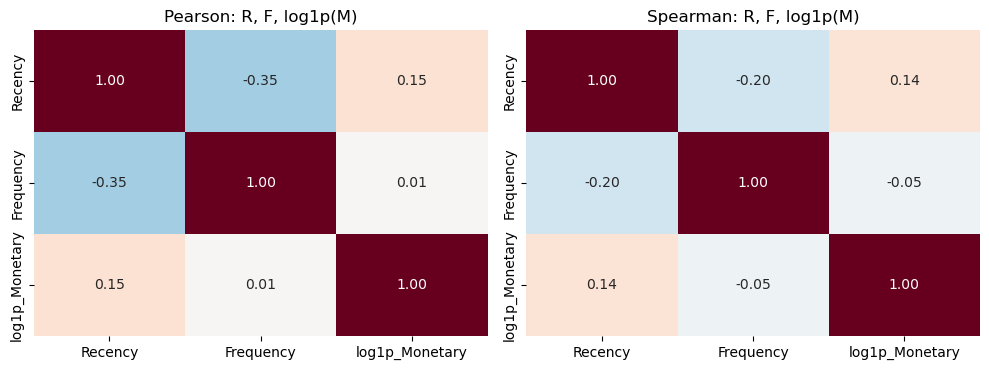


Share of total variance by principal component: [0.458 0.336 0.206]
Loadings on PC1:
 Recency           0.711
Frequency        -0.650
log1p_Monetary    0.268
dtype: float64

VIF (above about 5 suggests strong overlap): {'Recency': 1.17, 'Frequency': 1.14, 'log1p_Monetary': 1.03}

Correlation of risk/return features with activity features:
                     Recency  Frequency  log1p_Monetary
Mean_Weekly_Return    0.076      0.001           0.278
Beta                  0.069      0.083           0.241


In [88]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

act = all_feat[['Recency', 'Frequency', 'Monetary']].copy()
act['log1p_Monetary'] = np.log1p(act['Monetary'])
act = act[['Recency', 'Frequency', 'log1p_Monetary']]

# 1. Correlations
pearson  = act.corr(method='pearson')
spearman = act.corr(method='spearman')
print('PEARSON\n', pearson.round(3), '\n\nSPEARMAN\n', spearman.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, c, t in zip(ax, [pearson, spearman], ['Pearson', 'Spearman']):
    sns.heatmap(c, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=a, cbar=False)
    a.set_title(f'{t}: R, F, log1p(M)')
plt.tight_layout(); plt.savefig('outputs/rfm_correlations.png', dpi=200); plt.show()

# 2. Shared information after standardisation: PCA variance split
Z = (act - act.mean()) / act.std()
pca = PCA().fit(Z)
print('\nShare of total variance by principal component:', np.round(pca.explained_variance_ratio_, 3))
print('Loadings on PC1:\n', pd.Series(pca.components_[0], index=act.columns).round(3))

# 3. Variance inflation factor (how much of each feature the other two explain)
vif = {c: 1 / (1 - (act.drop(columns=c).apply(lambda s: s).pipe(
          lambda X: np.corrcoef(np.c_[X.values, act[c].values].T)[-1, :-1] @
                    np.linalg.solve(np.corrcoef(X.values.T), np.corrcoef(np.c_[X.values, act[c].values].T)[-1, :-1]))))
       for c in act.columns}
print('\nVIF (above about 5 suggests strong overlap):', {k: round(v, 2) for k, v in vif.items()})

# 4. Cross-block check: do activity features overlap with risk and return?
cross = all_feat[['Mean_Weekly_Return', 'Beta']].join(act).corr().loc[['Mean_Weekly_Return', 'Beta'], act.columns]
print('\nCorrelation of risk/return features with activity features:\n', cross.round(3))

### 2.5.2 Removal of Monetary (Ward, R and F only)

Shares: 486 | k = 4
Adjusted Rand index (R,F,M vs R,F only): 0.203
Silhouette: full = 0.289 | R,F only = 0.516

Cross-tabulation (rows = full RFM, columns = R,F only):
RF_only     0   1   2   3
Full_RFM                 
0           3  69   0  10
1         141   0  66   0
2          86   9  59   0
3          42   1   0   0

=== Full solution: R, F, log1p(M) ===
           n  R_median  F_median  M_median_USD_bn  M_IQR_USD_bn
Cluster                                                        
0         82      54.5       2.0            17.85         19.48
1        207      11.0       3.0            10.79          7.04
2        154      11.0       3.0            39.70         40.17
3         43      11.0       5.0            14.43          9.33

=== Reduced solution: R, F only ===
           n  R_median  F_median  M_median_USD_bn  M_IQR_USD_bn
Cluster                                                        
0        272      11.0       4.0            14.86         20.74
1         79      49.0  

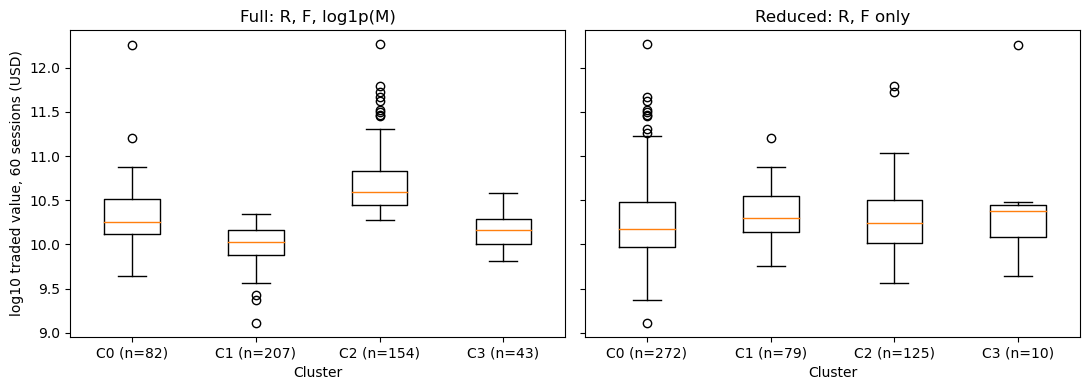

In [89]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score

K = SELECTED['Activity']                               # the selected Ward cluster count for the RFM matrix
idx = X_act.index                                       # same shares as the full RFM solution

# 1. Full solution: R, F, log1p(M), already standardised (X_act)
lab_full = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X_act)

# 2. Reduced solution: R and F only, standardised afresh
rf = all_feat.loc[idx, ['Recency', 'Frequency']]
X_rf = pd.DataFrame(StandardScaler().fit_transform(rf), index=idx, columns=rf.columns)
lab_rf = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X_rf)

# 3. Compare memberships
ari = adjusted_rand_score(lab_full, lab_rf)
print(f'Shares: {len(idx)} | k = {K}')
print(f'Adjusted Rand index (R,F,M vs R,F only): {ari:.3f}')
print(f'Silhouette: full = {silhouette_score(X_act, lab_full):.3f} | R,F only = {silhouette_score(X_rf, lab_rf):.3f}')
print('\nCross-tabulation (rows = full RFM, columns = R,F only):')
print(pd.crosstab(pd.Series(lab_full, index=idx, name='Full_RFM'), pd.Series(lab_rf, index=idx, name='RF_only')))

# 4. Traded value profiles of both solutions (original units)
d = all_feat.loc[idx, ['Recency', 'Frequency', 'Monetary']].copy()
d['log1p_M'] = np.log1p(d['Monetary'])

def prof(labels, name):
    g = d.assign(Cluster=labels).groupby('Cluster')
    out = pd.DataFrame({'n': g.size(),
                        'R_median': g['Recency'].median(),
                        'F_median': g['Frequency'].median(),
                        'M_median_USD_bn': (g['Monetary'].median() / 1e9).round(2),
                        'M_IQR_USD_bn': ((g['Monetary'].quantile(.75) - g['Monetary'].quantile(.25)) / 1e9).round(2)})
    print(f'\n=== {name} ==='); print(out.round(2).to_string())
    return out

p_full = prof(lab_full, 'Full solution: R, F, log1p(M)')
p_rf   = prof(lab_rf,   'Reduced solution: R, F only')

# 5. How much of the variation in traded value does each solution explain? (between-cluster share of variance)
def eta_sq(labels, col):
    s = d[col]; tot = ((s - s.mean()) ** 2).sum()
    betw = sum(len(g) * (g.mean() - s.mean()) ** 2 for _, g in s.groupby(labels))
    return betw / tot

for col in ['log1p_M', 'Recency', 'Frequency']:
    print(f'{col:10s} variance explained by clusters: full = {eta_sq(lab_full, col):.2f} | R,F only = {eta_sq(lab_rf, col):.2f}')

# 6. Plot: log10 traded value by cluster for both solutions
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, labs, t in zip(ax, [lab_full, lab_rf], ['Full: R, F, log1p(M)', 'Reduced: R, F only']):
    data = [np.log10(d.loc[labs == c, 'Monetary']) for c in range(K)]
    a.boxplot(data, labels=[f'C{c} (n={len(x)})' for c, x in enumerate(data)])
    a.set_title(t); a.set_xlabel('Cluster')
ax[0].set_ylabel('log10 traded value, 60 sessions (USD)')
plt.tight_layout(); plt.savefig('outputs/removal_of_monetary.png', dpi=200); plt.show()

## 3.2 Review of results and visualisation

### Visualisations for 3.2.1 (profiles, sector composition, overlap)

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import adjusted_rand_score

METHOD = "KMeans"                                   # or "Agglomerative"; use the same method in the text
rr, ac = f"Risk_Return_{METHOD}", f"Activity_{METHOD}"

# ---------- sector lookup (current GICS sector from the Wikipedia table) ----------
sector = (sp500_df.assign(Share=sp500_df["Symbol"].str.replace(".", "-", regex=False))
          .set_index("Share")["GICS Sector"].rename("Sector"))
prof = all_feat.join(final_labels).join(sector)
print("Shares without a sector:", int(prof["Sector"].isna().sum()))

# ---------- 1. profiles in ORIGINAL units ----------
rr_prof = prof.groupby(rr)[["Mean_Weekly_Return", "Beta"]].median()
ac_prof = prof.groupby(ac)[["Recency", "Frequency", "Monetary"]].median()
ac_prof["Monetary"] = ac_prof["Monetary"] / 1e9                    # USD billions
ac_prof = ac_prof.rename(columns={"Monetary": "Monetary_USD_bn"})
for t_, p_, c_ in [("Risk and return", rr_prof, rr), ("Trading activity", ac_prof, ac)]:
    p_["n"] = prof.groupby(c_).size(); p_["%"] = (p_["n"] / len(prof) * 100).round(1)
    print(f"\n{t_} clusters ({METHOD}), medians in original units"); print(p_.round(4).to_string())

# ---------- Figure 1: profile heatmaps (colour = z-score of cluster median, numbers = original units) ----------
def prof_heat(ax, tbl, title):
    vals = tbl.drop(columns=["n", "%"]); z = (vals - vals.mean()) / vals.std(ddof=0)
    z.index = [f"C{i} (n={tbl.loc[i, 'n']})" for i in tbl.index]
    sns.heatmap(z, annot=vals.round(3).astype(str).values, fmt="", cmap="RdBu_r", center=0, cbar=False, ax=ax)
    ax.set_title(title); ax.set_ylabel("")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
prof_heat(ax[0], rr_prof, f"Risk and return clusters ({METHOD})"); prof_heat(ax[1], ac_prof, f"Trading activity clusters ({METHOD})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_cluster_profiles.png", dpi=200); plt.show()

# ---------- Figure 2: sector composition of each cluster (100% stacked bars) ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for a, col, t_ in zip(ax, [rr, ac], ["Risk and return clusters", "Trading activity clusters"]):
    ct = pd.crosstab(prof[col], prof["Sector"], normalize="index") * 100
    ct.index = [f"C{i} (n={(prof[col] == i).sum()})" for i in ct.index]
    ct.plot(kind="barh", stacked=True, ax=a, colormap="tab20", legend=False, width=0.8)
    a.set_title(f"Sector mix: {t_}"); a.set_xlabel("% of cluster")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="center right", fontsize=8, title="GICS sector")
plt.tight_layout(rect=[0, 0, 0.84, 1]); plt.savefig(f"{OUT_DIR}/fig2_sector_composition.png", dpi=200); plt.show()

# ---------- Figure 3: over/under-representation vs the whole sample (lift; 1.0 = same as overall mix) ----------
overall = prof["Sector"].value_counts(normalize=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for a, col, t_ in zip(ax, [rr, ac], ["Risk and return", "Trading activity"]):
    lift = pd.crosstab(prof[col], prof["Sector"], normalize="index").div(overall, axis=1)
    sns.heatmap(lift, annot=True, fmt=".1f", cmap="RdBu_r", center=1, cbar=False, ax=a)
    a.set_title(f"Sector lift: {t_} (1.0 = same as overall)"); a.set_ylabel("Cluster"); a.set_xlabel("")
    a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_sector_lift.png", dpi=200); plt.show()

# ---------- Figure 4: do the two clusterings overlap? ----------
ct = pd.crosstab(prof[rr].rename("Risk/return cluster"), prof[ac].rename("Activity cluster"))
plt.figure(figsize=(5.5, 3.6)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Risk/return vs activity clusters (ARI = {adjusted_rand_score(prof[rr], prof[ac]):.2f})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_cluster_overlap.png", dpi=200); plt.show()

prof.to_csv(f"{OUT_DIR}/share_features_clusters_sectors.csv")
# Sensitivity figures already saved earlier: rfm_correlations.png and removal_of_monetary.png